# Business scenarios: what changes if windows are more flexible?

This notebook reads frozen results from `outputs/frozen/window_scenarios/` and `outputs/frozen/early_delivery/` to measure how much flexible window policies save in fleet size, distance and route duration, alongside the resulting plan churn, without invoking any solver during execution. Section 7 adds results from experiment B5 (`outputs/frozen/v2/B5_windows/` and `outputs/frozen/v2/B5_early/`), repeating both scenarios with warm starts between consecutive levels.

Preserving the strict separation defined in `reports/pre-analise-proposta.md` (section 2), whereas Layer A (notebooks 03 to 05) solves Solomon's hard VRPTW against SINTEF references, Layer B modifies problem constraints and therefore excludes any comparison with SINTEF. Each scenario is compared strictly against its own unmodified baseline plan (factor 1.0 or tolerance 0), solved with the same frozen configuration under a 30 s budget (Barr et al., 1995) across the 14 development instances.

Under Solomon's convention (Solomon, 1987; Toth & Vigo, 2014), vehicles arriving before window opening wait until service can begin, whereas real operations often accept early deliveries. The early-delivery scenario advances window opening by 25%, 50% or 100% of original width or drops the lower bound altogether (full tolerance up to window closing) while keeping closing times fixed; the widened-window scenario expands opening and closing bounds symmetrically by factors of 1.25, 1.5 and 2.0. Only input data change, while OR-Tools (Perron & Furnon, 2026) continues minimising fleet then distance (Bräysy & Gendreau, 2005a), making duration gains a secondary by-product. Effective settings from `config/experiment.toml` are inspected in section 1.

## 1. Environment setup

This section loads the 14 development instances, frozen logs from both business runs and effective configuration settings from `config/experiment.toml`. Summary tables report scenario parameters and verify completeness, feasibility on transformed instances and strict `dev`-set isolation.

In [1]:
LANG = "en"  # "pt" or "en"

import matplotlib.pyplot as plt
from IPython.display import display

from delivery_routing_vrptw import (
    benchmark,
    business,
    config,
    eda,
    paths,
    results,
    route_compare,
    v2_view,
    viz_business,
    viz_results,
)
from delivery_routing_vrptw.viz import setup_notebook_figures

setup_notebook_figures()

P = paths.data_paths()
R = paths.result_paths()
split = benchmark.read_split(P["split"])
cfg = config.load_config()
instances = results.load_dev_inputs(P["sintef_zip"], split)
window = results.load_window_scenarios(R["window_scenarios"], split)
early = results.load_early_delivery(R["early_delivery"], split)

display(eda.localize_columns(business.config_table(cfg, LANG), LANG))
display(eda.localize_columns(business.run_checks(window, early, split, LANG), LANG))

,Indicator,Value
0,Fleet strategy (frozen),fixed_cost
1,First solution (frozen),SAVINGS
2,Metaheuristic (frozen),GUIDED_LOCAL_SEARCH
3,Windows: width factors,"1, 1.25, 1.5, 2"
4,Windows: widening mode,symmetric
5,Windows: budget (s),30
6,Windows: instance set,dev
7,Early delivery: tolerances (fraction of the wi...,"0, 0.25, 0.5, 1, full"
8,Early delivery: replicates,3
9,Early delivery: budget (s),30


,Indicator,Value
0,Widened windows: cells,56
1,Widened windows: feasible in the verifier,56 / 56
2,Early delivery: cells,210
3,Early delivery: feasible in the verifier,210 / 210
4,Early delivery: replicates per cell,3
5,Distinct instances,14
6,Instances outside the development set,0


### Insight

Effective settings match the frozen solver (`fixed_cost` + `SAVINGS` + `GUIDED_LOCAL_SEARCH` at 30 s on `dev`), covering symmetry factors 1, 1.25, 1.5 and 2 (56 cells) and early tolerances 0, 0.25, 0.5, 1 and full across 3 replicates (210 cells). All runs are feasible against their respective transformed inputs, noting that feasibility on relaxed inputs confirms mathematical validity under hypothetical rules without guaranteeing customer acceptance or feasibility on the original hard instance. Section 2 evaluates symmetrical window widening.

## 2. Widened windows

The tables and figure compare factors 1.25, 1.5 and 2.0 against each instance's factor-1.0 baseline. Because distances across different fleet counts are incommensurable, outputs explicitly separate vehicle savings and percentage distance changes by fleet class (equal, reduced or larger fleet relative to baseline), alongside family-level breakdowns.

,Width factor,No. of instances,Vehicles saved (mean),Instances with fewer vehicles,Instances with more vehicles,Instances with equal fleet
0,1.25×,14,0.29,3,0,11
1,1.5×,14,0.57,7,0,7
2,2×,14,0.79,8,0,6


,Width factor,Fleet against the baseline plan,No. of instances,Vehicles saved (mean),"Distance change, mean (%)","Distance change, median (%)"
0,1.25×,equal fleet,11,0.00,-4.0,-3.6
1,1.25×,reduced fleet,3,1.33,-6.2,-8.7
2,1.5×,equal fleet,7,0.00,-4.4,-0.4
3,1.5×,reduced fleet,7,1.14,-7.2,-9.5
4,2×,equal fleet,6,0.00,-2.0,-1.1
5,2×,reduced fleet,8,1.38,-12.3,-11.5


,Family,No. of instances,×1.25 · vehicles saved (mean),×1.25 · instances with equal fleet,"×1.25 · distance, equal fleet (%, mean)",×1.5 · vehicles saved (mean),×1.5 · instances with equal fleet,"×1.5 · distance, equal fleet (%, mean)",×2 · vehicles saved (mean),×2 · instances with equal fleet,"×2 · distance, equal fleet (%, mean)"
0,C1,2,0.00,2,-0.1,0.00,2,-0.1,0.0,2,0.3
1,C2,2,0.00,2,-1.0,0.00,2,-1.0,0.0,2,4.1
2,R1,3,0.33,2,-3.6,0.67,1,-0.4,1.0,1,-2.1
3,R2,3,0.00,3,-4.7,0.67,1,-13.3,1.0,0,NaN
4,RC1,2,1.50,0,NaN,1.50,0,NaN,2.0,0,NaN
5,RC2,2,0.00,2,-10.5,0.50,1,-15.1,0.5,1,-18.9


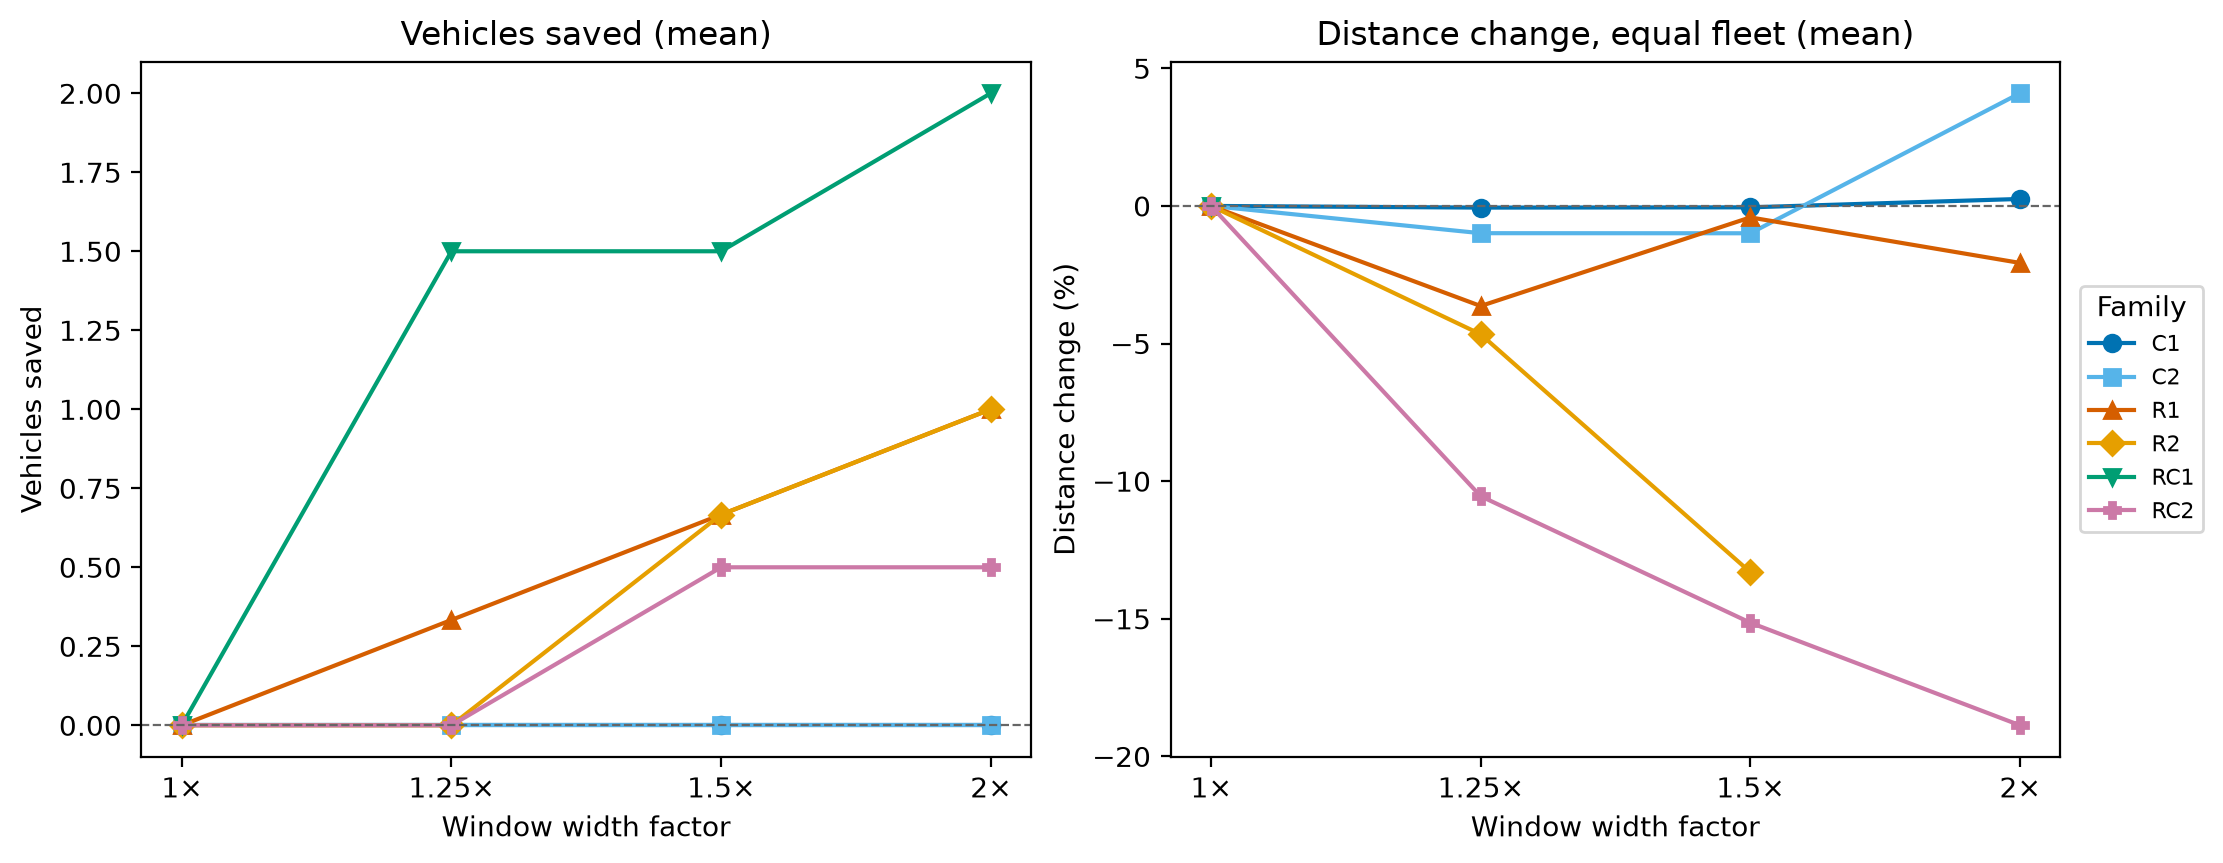

In [2]:
w_sum = business.window_results_summary(window)

display(eda.localize_columns(business.window_by_factor(w_sum), LANG))
display(eda.localize_columns(business.window_distance_by_fleet(w_sum, LANG), LANG))
display(eda.localize_columns(business.window_by_family(w_sum, LANG), LANG))

viz_business.plot_window_effect(w_sum, LANG)
plt.show()

### Insight

Relative to factor 1.0, window widening saved 0.29 vehicles on average at 1.25 (reducing fleets on 3 of 14 instances), 0.57 at 1.5 (7 of 14) and 0.79 at 2.0 (8 of 14), with zero instances expanding fleet size. Within unchanged fleets, mean distance shifted by −4.0% (11 instances at 1.25), −4.4% (7 at 1.5) and −2.0% (6 at 2.0), with medians of −3.6%, −0.4% and −1.1%; within reduced fleets, mean distance shifted by −6.2% (3 instances averaging 1.33 saved vehicles), −7.2% (7 averaging 1.14) and −12.3% (8 averaging 1.38), with medians of −8.7%, −9.5% and −11.5%.

By family, C1 and C2 saved zero vehicles across all factors with small bidirectional distance shifts (−1.0% to +4.1% across just 2 instances per cell), matching the capacity-bound behaviour established in notebook 02. Conversely, R1 saved 0.33, 0.67 and 1.00 vehicle; R2 saved 0.00, 0.67 and 1.00; RC1 saved 1.50, 1.50 and 2.00; and RC2 saved 0.00, 0.50 and 0.50, leaving sparse equal-fleet samples in R and RC. With only 2 or 3 instances per family in single 30 s runs, one-vehicle differences fall within wall-clock noise and means describe directional trends on synthetic inputs. Section 3 turns to early-delivery allowances.

## 3. Early delivery

To measure early-delivery effects, every tolerance level is compared against each instance's tolerance-0 baseline. Each cell (instance and tolerance) uses one coherent physical plan, the replicate at position ⌈R/2⌉ under lexicographic ordering (infeasibility, vehicles, distance), avoiding column-wise medians that mix metrics from distinct solutions.

Outcomes are stratified by fleet class and report route durations under two departure rules side by side: simultaneous departure at time zero and optimal departure shifted by forward time slack (Savelsbergh, 1992). Because starting at zero forces waiting before the first customer in baseline schedules, it inflates apparent duration reductions once early arrivals are permitted; optimal departure removes avoidable initial waiting in both plans, and the inflation column records that discrepancy in percentage points.

,Tolerated anticipation,Fleet against the baseline plan,No. of instances,Vehicles saved (mean),Distance (%),"Duration, depart at 0 (%)","Duration, optimal departure (%)",Inflation of depart-at-0 (p.p.),Last return (%)
0,25%,equal fleet,11,0.00,-2.2,-3.0,-2.1,1.0,-0.3
1,25%,reduced fleet,3,1.33,-0.9,-15.3,-9.7,5.6,1.4
2,50%,equal fleet,10,0.00,-5.3,-5.1,-3.7,1.3,-1.6
3,50%,reduced fleet,4,1.25,-5.4,-20.0,-13.2,6.8,-0.9
4,100%,equal fleet,8,0.00,-7.4,-9.0,-7.3,1.6,-5.3
5,100%,reduced fleet,6,1.17,-6.7,-19.1,-12.1,6.9,-2.6
6,full,equal fleet,7,0.00,-18.1,-25.5,-20.8,4.7,-21.6
7,full,reduced fleet,6,1.33,-11.0,-19.6,-11.7,7.9,-4.8
8,full,larger fleet,1,-1.00,8.1,0.7,0.7,0.0,0.0


,Family,Tolerated anticipation,Instances with equal fleet,Instances with reduced fleet,Instances with larger fleet
0,C1,25%,2,0,0
1,C1,50%,2,0,0
2,C1,100%,2,0,0
3,C1,full,1,0,1
4,C2,25%,2,0,0
5,C2,50%,2,0,0
6,C2,100%,2,0,0
7,C2,full,2,0,0
8,R1,25%,2,1,0
9,R1,50%,2,1,0


,Family,Indicator,No. of instances,25%,50%,100%,full
0,C1,"Route duration, optimal departure (%) · equal ...",2,-0.31,-0.18,-0.28,-0.90
1,C2,"Route duration, optimal departure (%) · equal ...",2,0.02,0.02,0.01,0.01
2,R1,"Route duration, optimal departure (%) · equal ...",3,-0.34,-2.43,NaN,NaN
3,R2,"Route duration, optimal departure (%) · equal ...",3,-3.39,-7.63,-13.45,-36.68
4,RC1,"Route duration, optimal departure (%) · equal ...",2,-5.48,-6.81,-6.11,NaN
5,RC2,"Route duration, optimal departure (%) · equal ...",2,-5.72,-10.04,-25.25,-34.79


,Family,Indicator,No. of instances,25%,50%,100%,full
0,C1,"Route duration, depart at 0 (%) · equal fleet",2,-0.82,-0.59,-0.79,-2.17
1,C2,"Route duration, depart at 0 (%) · equal fleet",2,0.38,0.47,-0.17,-0.17
2,R1,"Route duration, depart at 0 (%) · equal fleet",3,-2.55,-5.88,NaN,NaN
3,R2,"Route duration, depart at 0 (%) · equal fleet",3,-4.21,-7.56,-15.45,-43.72
4,RC1,"Route duration, depart at 0 (%) · equal fleet",2,-5.76,-10.59,-9.93,NaN
5,RC2,"Route duration, depart at 0 (%) · equal fleet",2,-9.14,-13.03,-29.23,-44.75


,Family,Indicator,No. of instances,25%,50%,100%,full
0,C1,Vehicles saved,2,0.00,0.00,0.00,-0.50
1,C2,Vehicles saved,2,0.00,0.00,0.00,0.00
2,R1,Vehicles saved,3,0.33,0.33,1.00,1.33
3,R2,Vehicles saved,3,0.00,0.33,0.33,0.00
4,RC1,Vehicles saved,2,1.00,1.00,1.00,1.50
5,RC2,Vehicles saved,2,0.50,0.50,0.50,0.50


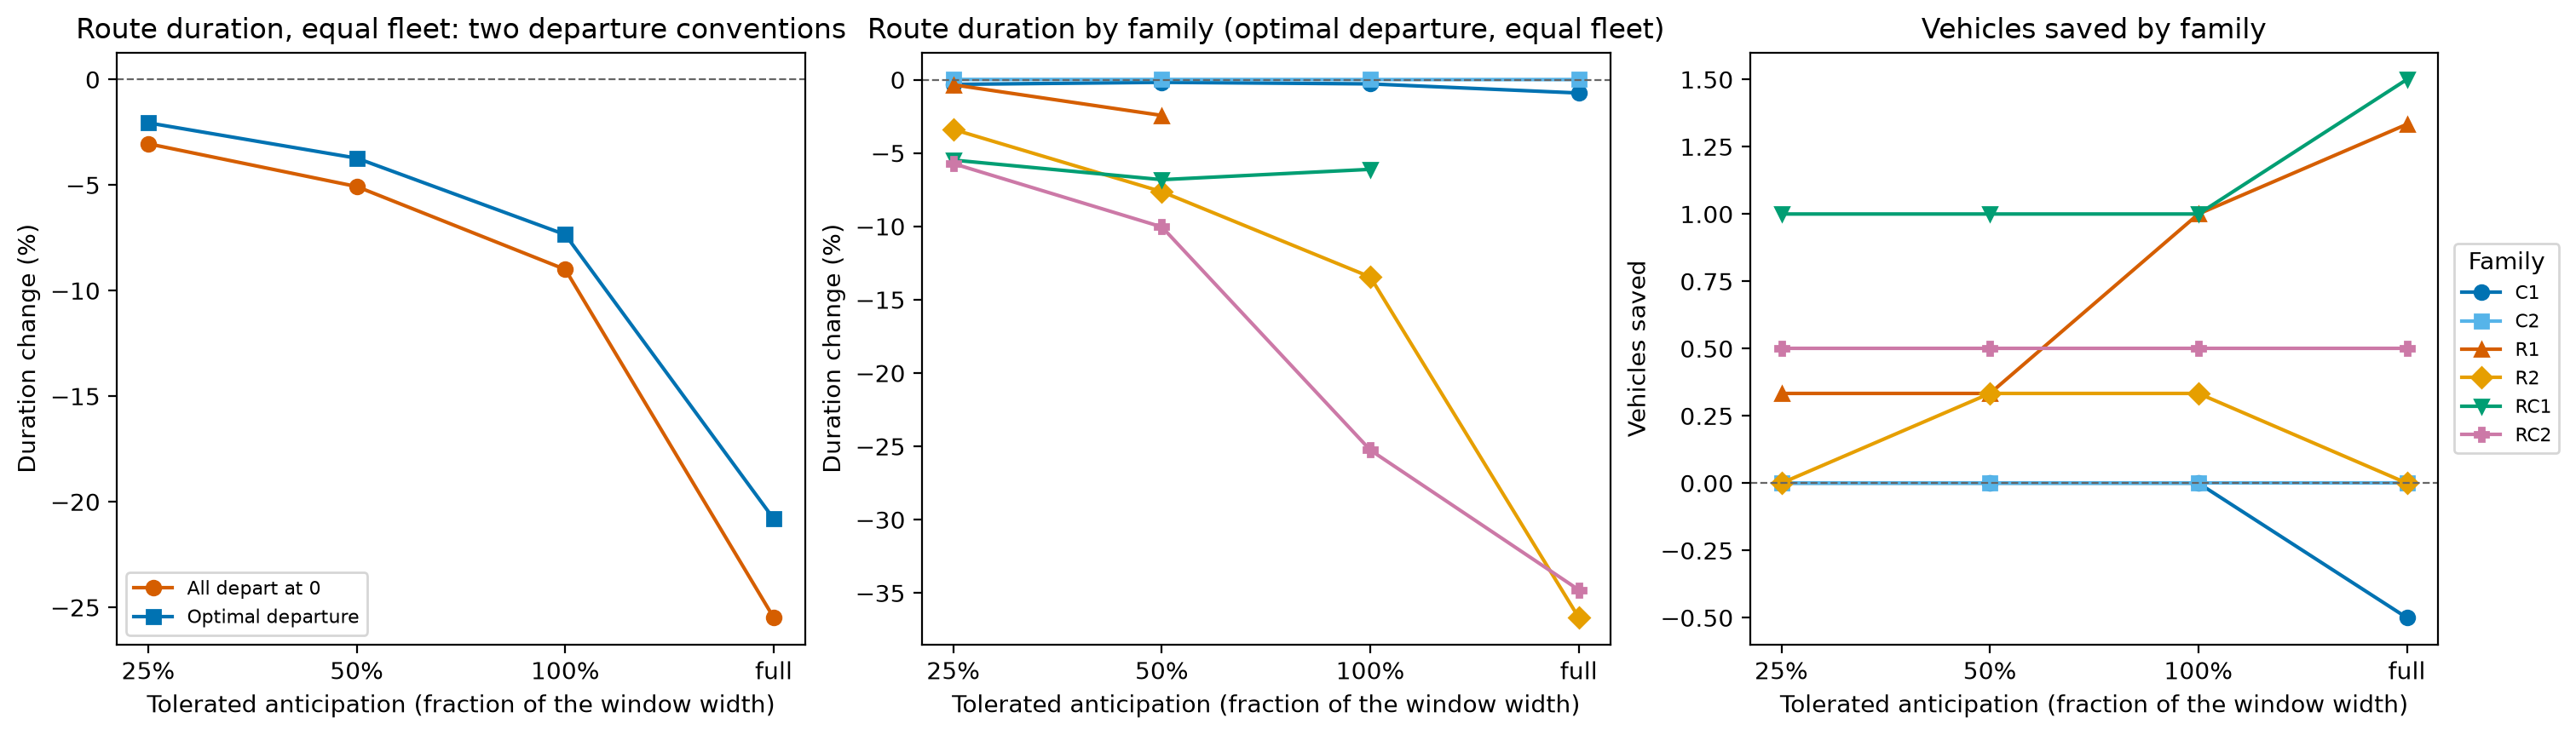

In [3]:
e_sum = business.early_results_summary(early)

display(eda.localize_columns(business.early_by_tolerance(e_sum, LANG), LANG))
display(eda.localize_columns(business.early_fleet_counts(e_sum, LANG), LANG))
display(eda.localize_columns(business.early_by_family(e_sum, "duration_min_pct", LANG, fleet="equal"), LANG))
display(eda.localize_columns(business.early_by_family(e_sum, "duration_pct", LANG, fleet="equal"), LANG))
display(eda.localize_columns(business.early_by_family(e_sum, "vehicles_saved", LANG), LANG))

viz_business.plot_early_effect(e_sum, LANG)
plt.show()

### Insight

Among instances maintaining baseline fleets (11, 10, 8 and 7 instances across 25%, 50%, 100% and full tolerance), optimal-departure route duration moved by −2.1%, −3.7%, −7.3% and −20.8%, while distance fell by −2.2%, −5.3%, −7.4% and −18.1% (with last depot return shifting −0.3%, −1.6%, −5.3% and −21.6%). Under depart-at-zero conventions, duration drops would appear 1.0, 1.3, 1.6 and 4.7 percentage points larger. Within reduced-fleet instances (3, 4, 6 and 6 instances saving 1.17 to 1.33 vehicles), optimal duration shifted −9.7%, −13.2%, −12.1% and −11.7% (overstated by 5.6 to 7.9 points at departure zero) and distance changed −0.9%, −5.4%, −6.7% and −11.0%; only C106 under full tolerance used 1 extra vehicle (+8.1% distance and +0.7% duration).

By family under equal fleets and optimal departure at full tolerance, duration fell −36.7% in R2 (3 instances) and −34.8% in RC2 (1 instance), versus marginal shifts of −0.9% in C1 (1 instance) and +0.0% in C2 (2 instances). All R1 and RC1 instances reduced fleet sizes under full tolerance, saving 1.33 and 1.50 vehicles on average (versus 0.00 in R2 and 0.50 in RC2). This split aligns with large waiting buffers in long-horizon series-2 instances, recalling that time savings remain a side effect across 14 instances and 30 s replicates. Section 4 measures route churn required to achieve these savings.

## 4. Reallocation of deliveries

Each early-delivery plan is compared with the tolerance-0 plan of the same replicate, weighing scenario churn against the noise floor observed across replicates of the baseline schedule. Tables report median percentages across instances and replicates for customers moved to another vehicle (greedy overlap matching), same-route customer pairs kept together, overall pair agreement (Rand index; Rand, 1971) and preserved arcs, followed by family medians.

,Tolerated anticipation,Comparisons,Customers reassigned (%),Pairs kept (%),Pair agreement (%),Arcs kept (%)
0,25%,42,43.0,54.2,90.4,39.6
1,50%,42,39.0,48.7,90.8,39.3
2,100%,42,40.5,52.7,90.9,36.1
3,full,42,33.5,53.4,89.8,25.8
4,noise,42,0.0,100.0,100.0,100.0


,Family,25%,50%,100%,full,noise
0,C1,2.5,2.5,2.5,6.0,0.0
1,C2,0.0,1.0,1.0,1.0,0.0
2,R1,43.0,43.0,43.0,44.0,0.0
3,R2,47.0,57.0,51.0,29.0,0.0
4,RC1,31.0,33.0,36.0,43.0,0.0
5,RC2,61.0,56.0,45.0,51.0,0.0


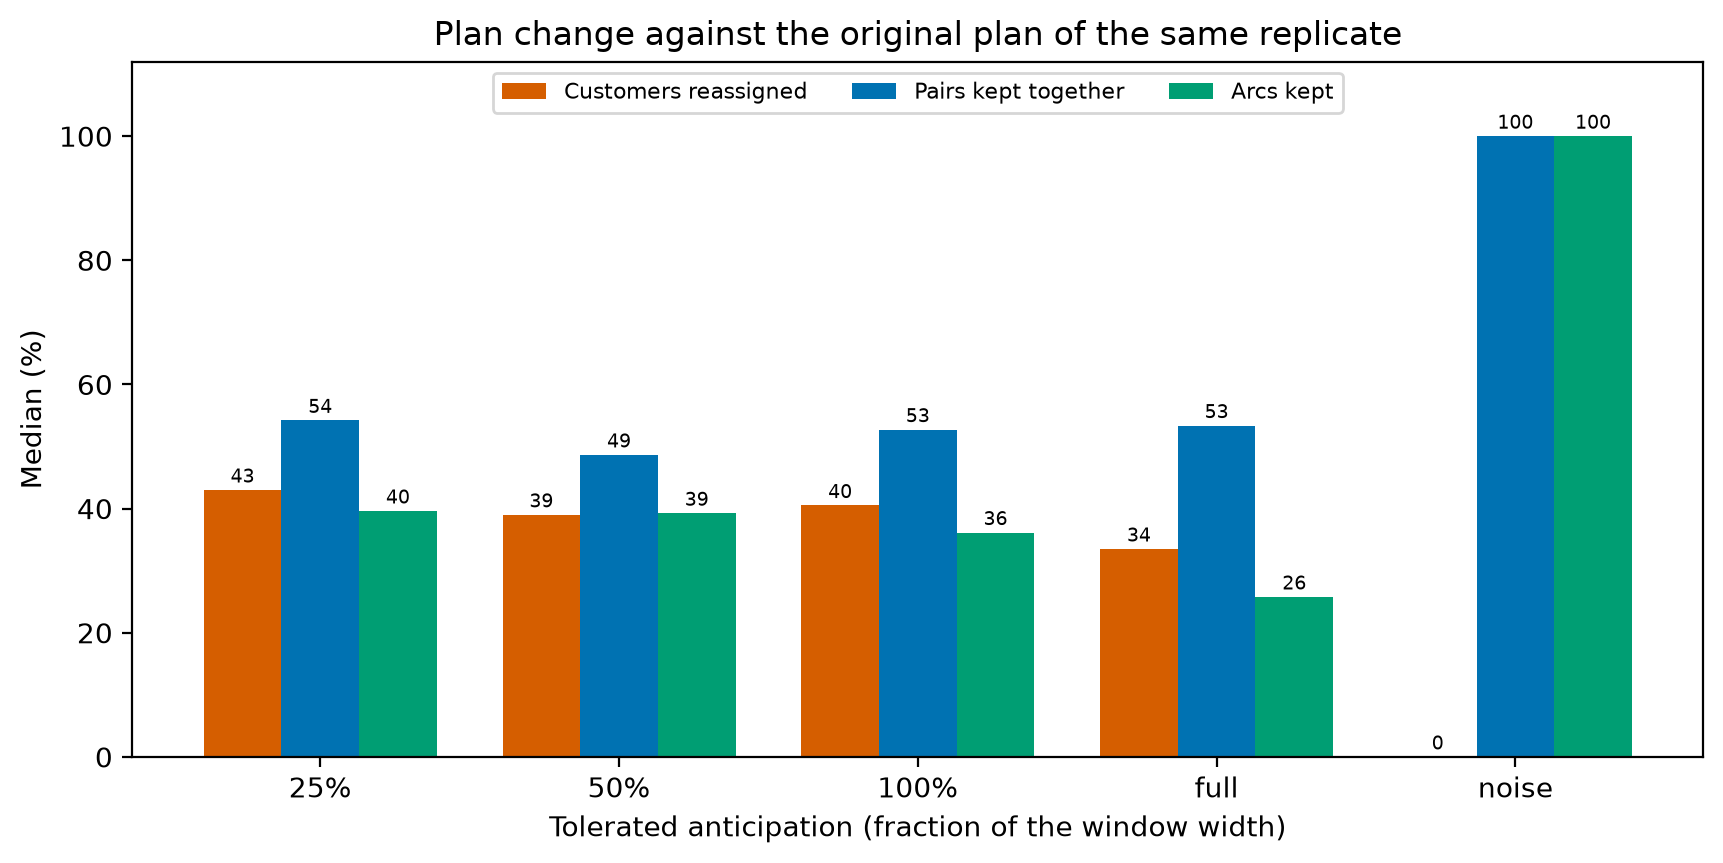

In [4]:
realloc = route_compare.reallocation_table(early)

display(eda.localize_columns(business.reallocation_display(realloc, LANG), LANG))
display(eda.localize_columns(business.reallocation_by_family(realloc, LANG), LANG))

viz_business.plot_reallocation(realloc, LANG)
plt.show()

### Insight

Even minimal anticipation (25%) reassigns 43.0% of customers in median (39.0% at 50%, 40.5% at 100% and 33.5% at full, versus 0.0% noise floor), preserving only 54.2% to 53.4% of customer pairs and 39.6% to 25.8% of arcs (versus 100% at baseline). Hence time and fleet savings stem from thorough route restructuring rather than minor local edits. In C families, where flexibility yields negligible gains, reallocation stays between 0.0% and 6.0%, whereas it rises to 43.0%–44.0% in R1, 29.0%–57.0% in R2, 31.0%–43.0% in RC1 and 45.0%–61.0% in RC2. Although the baseline noise floor was zero on an idle machine, ±1 vehicle fluctuations occur under contention (section 6) and greedy matching depends on the overlap criterion. Section 5 inspects a concrete visual example.

## 5. Before-and-after example

Among instances saving at least one vehicle under full tolerance, the side-by-side maps depict replicate 1 of the case achieving the largest relative reduction in optimal-departure duration, comparing the baseline plan on the left against full early delivery on the right.

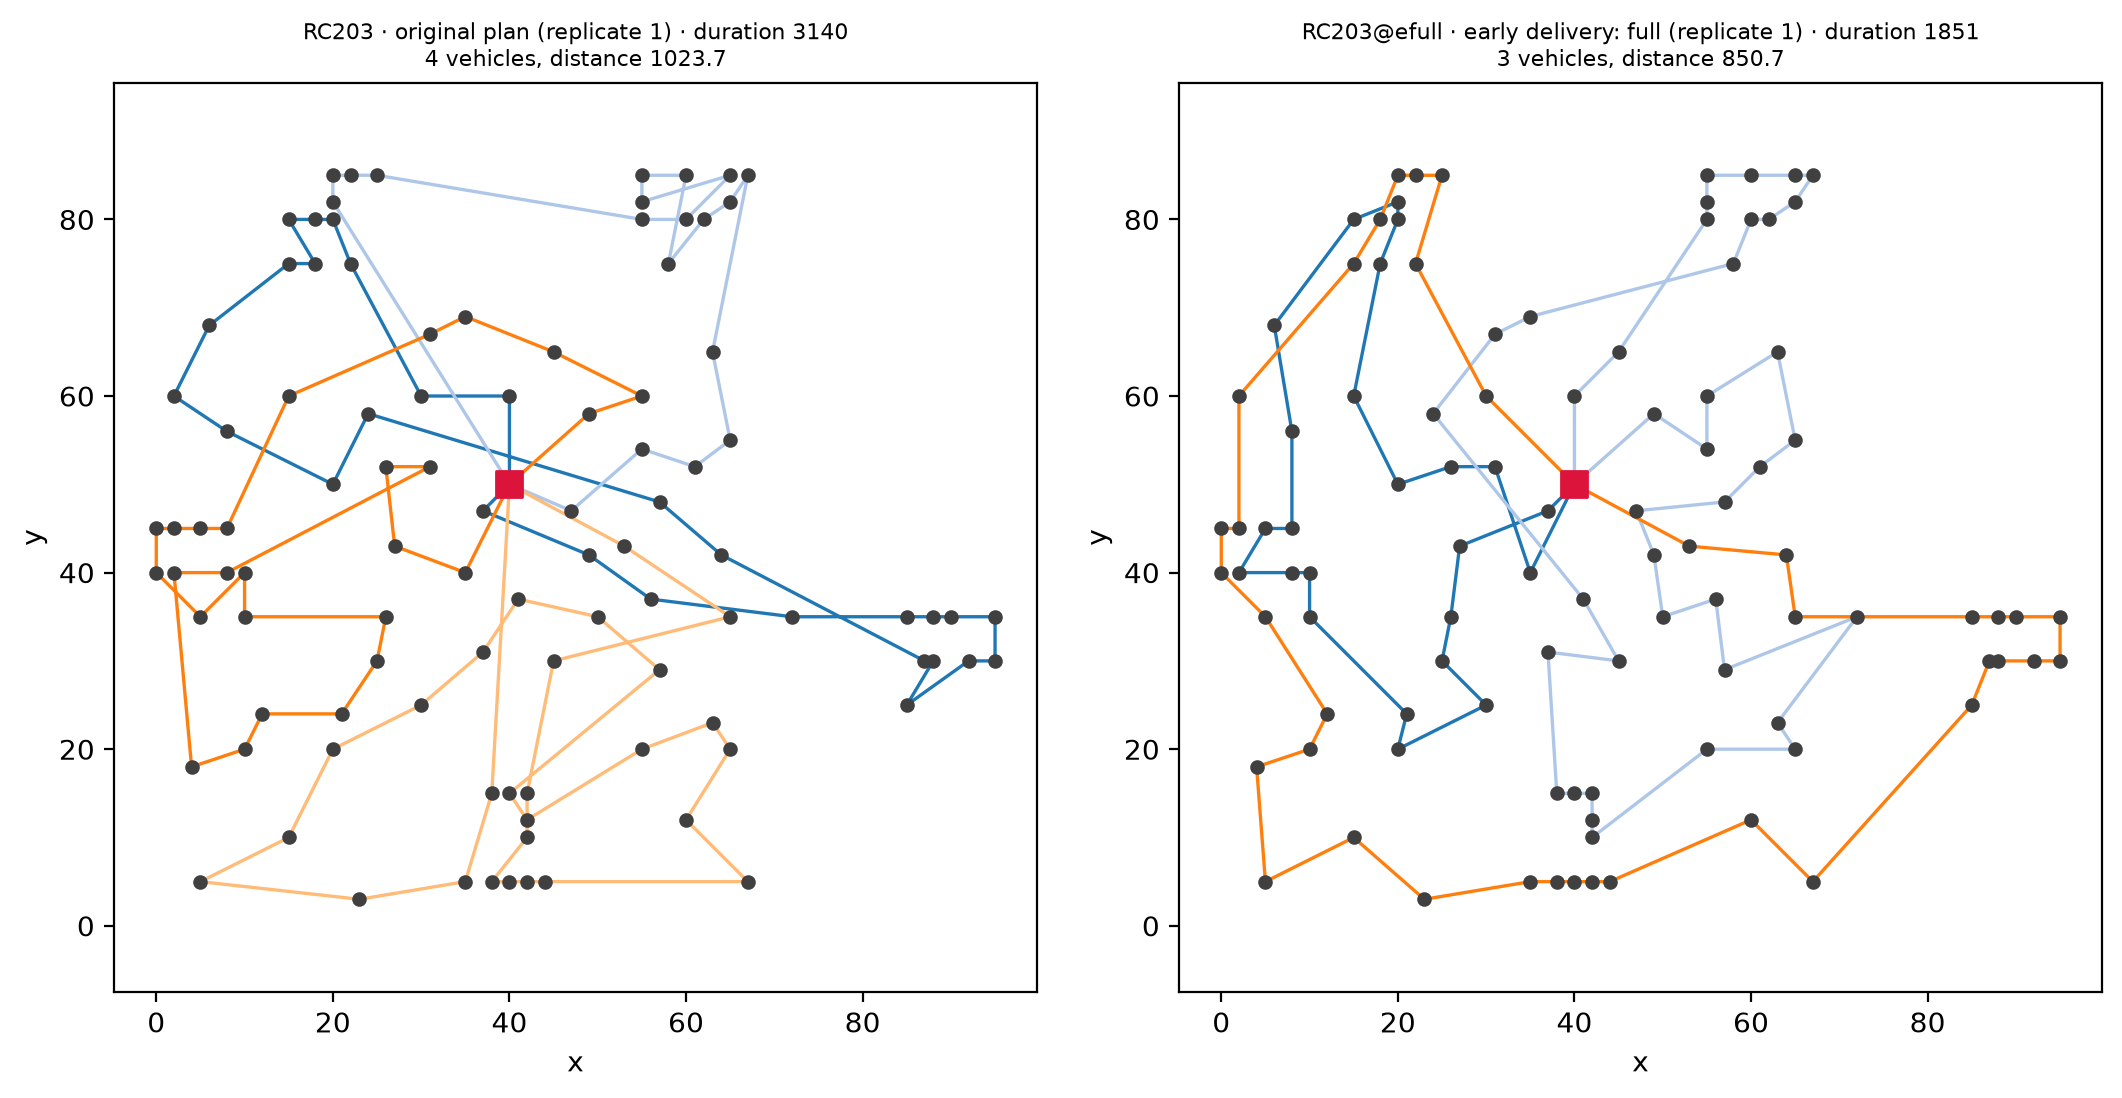

In [5]:
example = business.pick_early_example(e_sum)

viz_results.plot_route_panels(business.before_after_panels(example, instances, early, LANG), LANG)
plt.show()

### Insight

Selection chose RC203, where replicate 1 (representative at both levels and identical across all 3 replicates) drops from 4 vehicles, 1023.7 distance and 3140 optimal duration down to 3 vehicles, 850.7 distance (−16.9%) and 1851 duration (−41.1%). Whereas the original routes cross and overlap across four regions, the full-anticipation plan partitions into three cleaner geographic sectors with extensively reshuffled assignments matching section 4's reallocation rates. Because RC203 was picked specifically for strong fleet and time gains (in contrast with C106), it illustrates a solver side effect with arbitrary route colours. Section 6 audits noise and monotonicity across frozen records.

## 6. Limitations measured on the data

Audit tables extract baseline replicate noise in early delivery, discrepancies between an initial contended widened-window run and the clean run (kept strictly as evidence of machine-load variance), and non-monotonic cells, cases where a more permissive level produced a lexicographically worse plan (more vehicles or longer distance at equal fleet) than a stricter level of the same instance, impossible at exact optimality and reflecting time-limited cold searches without warm starts in v1.

In [6]:
contended = results.load_window_scenarios(R["window_scenarios_contended"], split)

display(eda.localize_columns(business.noise_floor_table(e_sum, realloc, LANG), LANG))
display(eda.localize_columns(business.run_comparison_table(window, contended, LANG), LANG))
display(eda.localize_columns(business.nonmonotonic_cases(w_sum, e_sum, LANG), LANG))

,Indicator,Value
0,Replicates of the original plan per instance,3
1,Instances with a different fleet across origin...,0 / 14
2,Instances with a different distance across ori...,1 / 14
3,Customers reassigned between original-plan rep...,0.0


,Indicator,Value
0,Cells compared (instance × factor),56
1,Cells with a different fleet between the two runs,4 / 56
2,Largest fleet difference (vehicles),1
3,Cells with a different distance between the tw...,22 / 56
4,Instances with a different fleet at factor 1.0,2 / 14


,Scenario,Instance,Level,Vehicles,Distance,Fleet of the best plan at a less permissive level,Distance of the best plan at a less permissive level,Worsening
0,Widened windows,C103,1.5×,10,858.1,10,857.5,distance (equal fleet)
1,Widened windows,C106,1.25×,10,829.4,10,828.9,distance (equal fleet)
2,Widened windows,C106,2×,10,859.3,10,828.9,distance (equal fleet)
3,Widened windows,C203,2×,3,650.1,3,588.5,distance (equal fleet)
4,Widened windows,R108,1.5×,10,966.3,10,962.5,distance (equal fleet)
5,Widened windows,RC108,2×,10,1075.9,10,1068.0,distance (equal fleet)
6,Early delivery,C103,50%,10,866.5,10,828.1,distance (equal fleet)
7,Early delivery,C103,100%,10,866.5,10,828.1,distance (equal fleet)
8,Early delivery,C103,full,10,833.2,10,828.1,distance (equal fleet)
9,Early delivery,C106,full,11,895.9,10,828.9,fleet


### Insight

In idle-machine early delivery, all 3 baseline replicates produced identical fleets on all 14 instances and identical distances on 13 (0.0% customer churn). Conversely, comparing the earlier contended run against the clean run showed fleet differences on 4 of 56 cells (up to 1 vehicle) and distance shifts on 22 of 56, confirming non-zero solver variance under load. Under strict lexicographic order, 20 v1 cells proved non-monotonic: 6 in widened windows (all equal-fleet distance worsenings, up to 650.1 versus 588.5 in C203 ×2) and 14 in early delivery (2 fleet worsenings under full tolerance, C106 rising from 10 to 11 and R202 from 3 to 4, plus 12 equal-fleet distance worsenings). Because all 14 instances are synthetic without modelled change costs or SINTEF comparisons, section 7 tests whether warm starting eliminates these anomalies.

## 7. Warm start between levels (B5)

Because every stricter solution remains mathematically feasible under any subsequent relaxation, experiment B5 (`reports/protocolo-v2.md`) repeated both scenarios across the 14 development instances by warm-starting each level from the preceding level's plan (`ReadAssignmentFromRoutes`). To isolate warm-starting effects, runs kept the v1 configuration and 30 s budget (1 replicate for widened windows and 3 for early delivery), saving frozen outputs under `outputs/frozen/v2/B5_windows/` and `outputs/frozen/v2/B5_early/` without SINTEF comparisons.

The tables and plot verify warm-start execution counts, compare lexicographic non-monotonicity against v1 and display vehicle savings across levels for both versions.

,Scenario,Cells,No. of instances,Cells with warm start,Cells without start (1st level),Feasible
0,Widened windows,56,14,42,14,56
1,Early delivery,210,14,168,42,210


,Scenario,Version,Non-monotonic cells,Fleet worsenings,Distance worsenings (equal fleet)
0,Widened windows,v1 (no warm start),6,0,6
1,Widened windows,v2 (warm start),0,0,0
2,Early delivery,v1 (no warm start),14,2,12
3,Early delivery,v2 (warm start),0,0,0


,Scenario,Level,Mean vehicles (v1),"Vehicles saved, mean (v1)","Vehicles saved, total (v1)","Mean vehicles (v2, warm start)","Vehicles saved, mean (v2)","Vehicles saved, total (v2)"
0,Widened windows,1×,7.29,0.00,0,7.36,0.00,0
1,Widened windows,1.25×,7.00,0.29,4,7.07,0.29,4
2,Widened windows,1.5×,6.71,0.57,8,6.86,0.50,7
3,Widened windows,2×,6.50,0.79,11,6.50,0.86,12
4,Early delivery,0%,7.36,0.00,0,7.36,0.00,0
5,Early delivery,25%,7.07,0.29,4,7.07,0.29,4
6,Early delivery,50%,7.00,0.36,5,7.07,0.29,4
7,Early delivery,100%,6.86,0.50,7,6.71,0.64,9
8,Early delivery,full,6.86,0.50,7,6.64,0.71,10


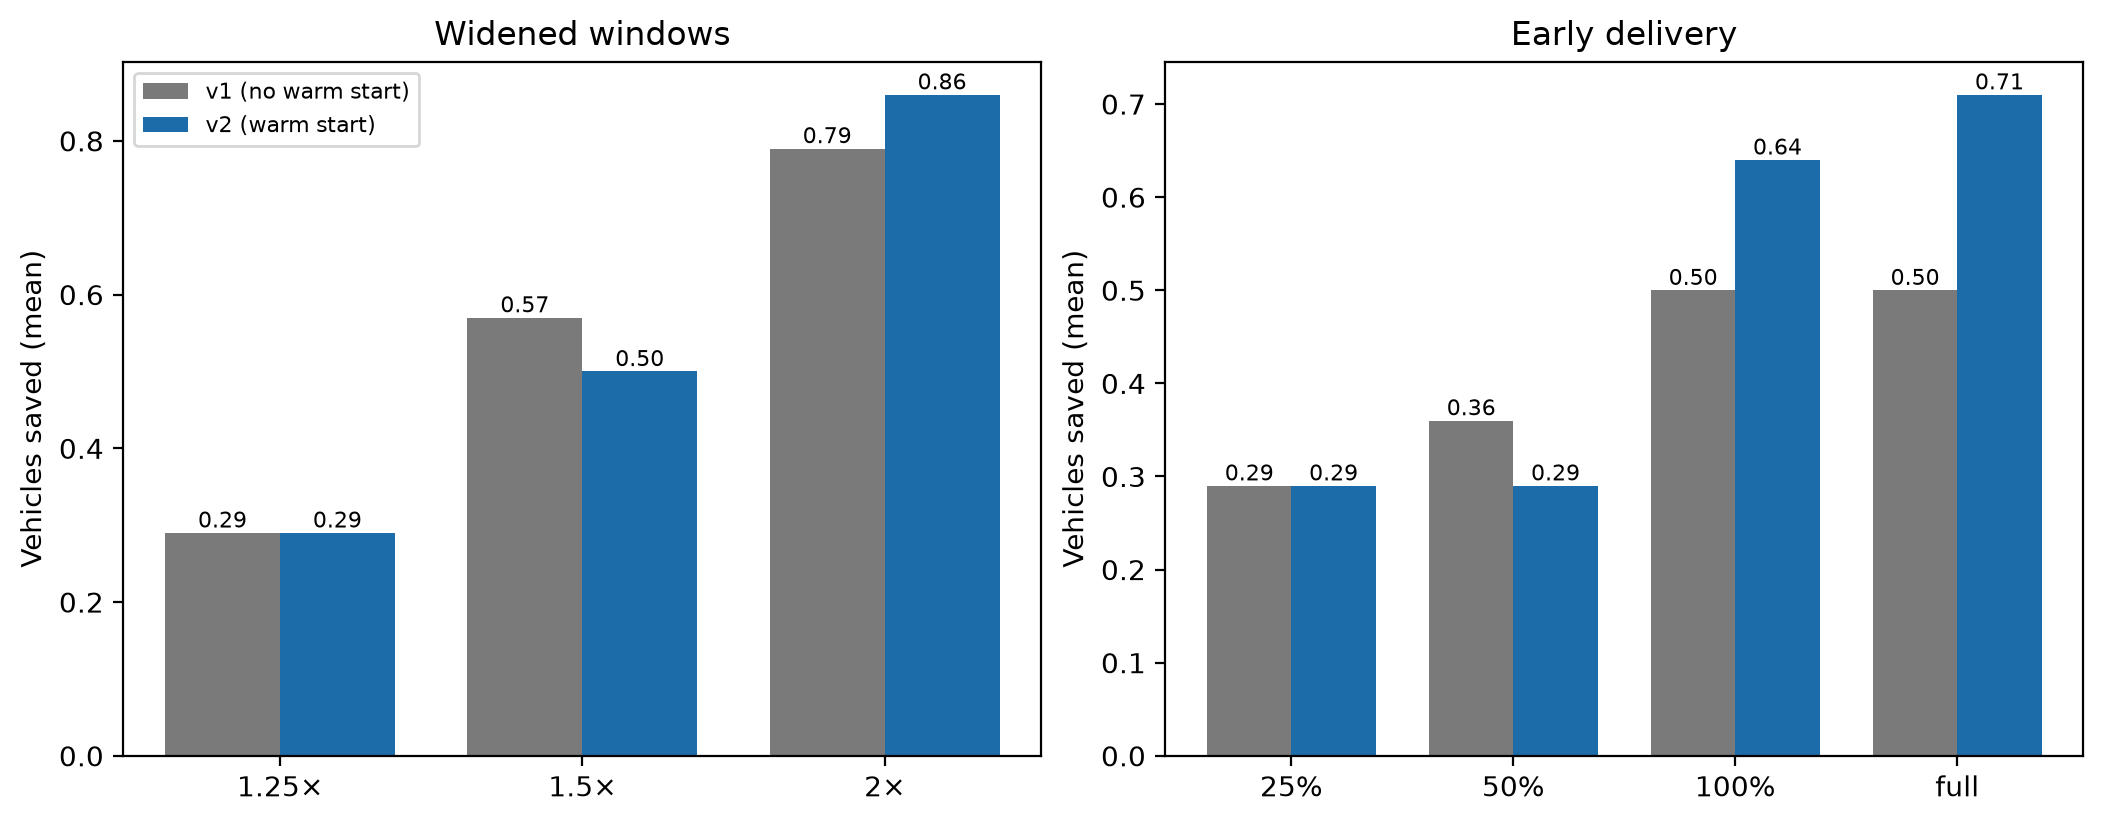

In [7]:
window_v2 = results.load_window_scenarios(R["v2_B5_windows"], split)
early_v2 = results.load_early_delivery(R["v2_B5_early"], split)

display(eda.localize_columns(v2_view.layerb_warm_counts(window_v2, early_v2, LANG), LANG))
display(eda.localize_columns(v2_view.layerb_nonmonotonic(window, window_v2, early, early_v2, LANG), LANG))
display(eda.localize_columns(v2_view.layerb_levels(window, window_v2, early, early_v2, LANG, include_base=True), LANG))

viz_business.plot_warm_start(v2_view.layerb_levels(window, window_v2, early, early_v2, LANG), LANG)
plt.show()

### Insight

All 56 widened-window cells and 210 early-delivery cells proved feasible, with 42 and 168 runs warm-started from the prior level while ladder starts (14 and 42) ran cold. Warm starting eliminated every non-monotonic cell, dropping counts from 6 to 0 in widened windows and from 14 to 0 in early delivery, confirming that section 6 anomalies stemmed from cold independent restarts rather than problem structure.

Vehicle savings relative to each version's baseline varied slightly in both directions (for example, 0.79 in v1 versus 0.86 in v2 at windows ×2, and 0.50 versus 0.71 under full early delivery), reflecting minor baseline differences within expected 30 s clock noise of ±1 vehicle. While B5 resolves monotonicity, main tables in sections 2 through 5 preserve original v1 runs.

## 8. Business synthesis

Flexibility benefits concentrate exclusively in the R and RC families, where time windows dictate fleet size. Doubling window width saves 0.79 vehicles on average (cutting fleets in 8 of 14 instances, with −12.3% distance where fleets drop and −2.0% where unchanged), while unrestricted early delivery saves 0.50 vehicles on average (lowering equal-fleet distance by −18.1% and optimal duration by −20.8%, reaching −36.7% in R2 and −34.8% in RC2, alongside −11.0% and −11.7% in reduced-fleet cases). In capacity-bound C families, window relaxations save zero vehicles and deliver negligible duration changes (−0.9% to +0.0%).

Interpretation requires attention to departure metrics and operational disruption. Distance and duration are comparable solely within matching fleet classes, naive depart-at-zero conventions inflate duration gains by 1.0 to 7.9 percentage points over optimal departure, and duration improvements remain side effects of fleet-and-distance optimisation. Practically, even 25% early anticipation reassigns roughly 40% of customers and alters over 60% of route arcs, requiring operational gains to outweigh driver and routing disruption. Although warm starts in B5 removed all 20 non-monotonic v1 cells without altering qualitative business conclusions, findings cover 14 synthetic instances without SINTEF comparisons or empirical customer-acceptance models.

## References

- Barr, R. S., Golden, B. L., Kelly, J. P., Resende, M. G. C., & Stewart, W. R. (1995). Designing and reporting on computational experiments with heuristic methods. *Journal of Heuristics, 1*(1), 9–32.
- Bräysy, O., & Gendreau, M. (2005a). Vehicle routing problem with time windows, Part I: Route construction and local search algorithms. *Transportation Science, 39*(1), 104–118.
- Perron, L., & Furnon, V. (2026). *OR-Tools* (Version 9.15) [Computer software]. Google. https://developers.google.com/optimization/
- Rand, W. M. (1971). Objective criteria for the evaluation of clustering methods. *Journal of the American Statistical Association, 66*(336), 846–850.
- Savelsbergh, M. W. P. (1992). The vehicle routing problem with time windows: Minimizing route duration. *ORSA Journal on Computing, 4*(2), 146–154.
- Solomon, M. M. (1987). Algorithms for the vehicle routing and scheduling problems with time window constraints. *Operations Research, 35*(2), 254–265.
- Toth, P., & Vigo, D. (Eds.). (2014). *Vehicle routing: Problems, methods, and applications* (2nd ed.). SIAM.